# The Dynkin Classification in Computational Perspective

**A matrix-first companion to the doctoral thesis**

**Abstract.** This notebook presents a compact, executable view of the A/D classification of
quasi-Cartan matrices developed in the thesis *La clasificación Dynkin en perspectiva
computacional*. The matrix is the primary object; a mixed bigraph is a labeled incidence view
that is drawn only when it represents the matrix faithfully. We compute a flation, certify the
A-type example A9, construct D13 by gluing five A-type pieces onto an odd D-core, and obtain D8
from A9 by A-cyclization. A final table separates finite types, classifier-only outcomes, and a
matrix that has no faithful bigraph. Every structural certificate is checked by the library.

**Keywords:** quasi-Cartan matrix, mixed bigraph, flation, Dynkin type, block-cut tree,
D-core gluing, A-cyclization.

## 1. Setup and notation

The notebook installs the latest DynkinLab from the project's git default branch when it runs in
Colab and uses the local checkout otherwise. No package, commit, tag, or dependency version is
pinned. The mathematical work is done by the public `dynkinlab` surface; the path notation,
matrix tables, drawability test, and drawing helpers below are local presentation code.

In [1]:
import subprocess
import sys

if "google.colab" in sys.modules:
    subprocess.check_call(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "-U",
            "dynkinlab @ git+https://github.com/knkillname/dynkinlab.git@main",
        ],
    )

In [2]:
import html
import re
from collections.abc import Hashable, Iterable, Mapping, Sequence

import matplotlib.pyplot as plt
from IPython.display import HTML, Markdown, display
from matplotlib.axes import Axes
from matplotlib.patches import FancyArrowPatch

import dynkinlab
from dynkinlab import (
    Bigraph,
    BlockCutTree,
    ClassificationStatus,
    DCore,
    DynkinType,
    EdgeMultiset,
    EdgeStyle,
    Inertia,
    QuasiCartanMatrix,
)

dynkinlab.display.options.matrix_index_base = 1
dynkinlab.display.options.expanded_form_dimension_limit = 3
dynkinlab.display.options.bigraph_layout_seed = 7

**Path notation.** The worked examples use the thesis's compact path notation. Each line is a
path, `#` starts a comment, and whitespace or commas separate tokens. The six edge operators act
on the two endpoints of the matrix entry:

| operator | meaning | entries |
|---|---|---|
| `--` | solid edge | `-1, -1` |
| `..` | dotted edge | `+1, +1` |
| `->` | solid arrow left-to-right | `-1, -2` |
| `<-` | solid arrow right-to-left | `-2, -1` |
| `.>` | dotted arrow left-to-right | `+1, +2` |
| `<.` | dotted arrow right-to-left | `+2, +1` |

The reverse magnitude is fixed at two because every arrow in these examples has multiplicity two.
Labels default to first appearance; an explicit `labels` argument fixes matrix order and rejects
paths that introduce a label outside it. Repeating a pair with different entries is an error.

In [3]:
_EDGE_VALUES: dict[str, tuple[int, int]] = {
    "--": (-1, -1),
    "..": (1, 1),
    "->": (-1, -2),
    "<-": (-2, -1),
    ".>": (1, 2),
    "<.": (2, 1),
}
_TOKEN = re.compile(r"[A-Za-z_][A-Za-z0-9_]*|\d+|--|\.\.|->|<-|\.>|<.")
_PATH_MIN_TOKENS = 3
_TOKEN_PAIR = 2
_ARROW_MULTIPLICITY = 2


def _as_label(token: str) -> Hashable:
    """Return an integer label for a decimal token and a string label otherwise."""
    return int(token) if token.isdigit() else token


def graph(text: str, labels: Iterable[Hashable] | None = None) -> Bigraph:
    """Build a labeled bigraph from triangle-free path-notation lines."""
    pinned = None if labels is None else tuple(labels)
    order: list[Hashable] = []
    declared: dict[frozenset[Hashable], dict[tuple[Hashable, Hashable], int]] = {}

    def remember(label: Hashable) -> None:
        if pinned is not None and label not in pinned:
            raise ValueError(f"label {label!r} is outside the explicit label order")
        if label not in order:
            order.append(label)

    for raw_line in text.splitlines():
        line = raw_line.split("#", 1)[0].strip()
        if not line:
            continue
        tokens: list[str] = []
        position = 0
        for match in _TOKEN.finditer(line):
            if line[position : match.start()].strip(" \t,"):
                raise ValueError(f"invalid token in path: {raw_line!r}")
            tokens.append(match.group())
            position = match.end()
        if line[position:].strip(" \t,"):
            raise ValueError(f"invalid token in path: {raw_line!r}")
        if len(tokens) < _PATH_MIN_TOKENS or len(tokens) % _TOKEN_PAIR == 0:
            raise ValueError(f"invalid path: {raw_line!r}")

        current = _as_label(tokens[0])
        remember(current)
        for position in range(1, len(tokens), 2):
            operator = tokens[position]
            if operator not in _EDGE_VALUES:
                raise ValueError(f"unknown edge operator: {operator!r}")
            following = _as_label(tokens[position + 1])
            remember(following)
            if current == following:
                raise ValueError("an edge requires distinct endpoints")
            forward, backward = _EDGE_VALUES[operator]
            pair = frozenset((current, following))
            values = {(current, following): forward, (following, current): backward}
            previous = declared.get(pair)
            if previous is not None and previous != values:
                raise ValueError(f"conflicting declarations for {current!r} and {following!r}")
            declared[pair] = values
            current = following

    matrix_labels = tuple(order) if pinned is None else pinned
    index = {label: position for position, label in enumerate(matrix_labels)}
    size = len(matrix_labels)
    rows = [[2 if row == column else 0 for column in range(size)] for row in range(size)]
    for values in declared.values():
        for (source, target), value in values.items():
            rows[index[source]][index[target]] = value
    return Bigraph(QuasiCartanMatrix(rows), matrix_labels)

**Matrix tables.** The display helper below labels every row and column. It is used instead of an
index-based rendering because D8 has the non-contiguous labels `(1, 2, 3, 4, 5, 7, 8, 9)`. Wide
matrices can be collapsed without changing the underlying value.

In [4]:
def matrix_html(
    matrix: QuasiCartanMatrix,
    labels: Iterable[Hashable],
    *,
    caption: str | None = None,
    collapse: bool = False,
) -> str:
    """Return a horizontally scrollable HTML table with explicit labels."""
    normalized = tuple(labels)
    if len(normalized) != matrix.dimension:
        raise ValueError("labels must match the matrix dimension")
    header = "".join(
        f'<th scope="col" style="padding:0.25rem 0.45rem;border:1px solid #d5d8dc;">'
        f"{html.escape(str(label))}</th>"
        for label in normalized
    )
    body = []
    for label, row in zip(normalized, matrix.entries, strict=True):
        cells = "".join(
            f'<td style="padding:0.25rem 0.45rem;border:1px solid #d5d8dc;'
            f'text-align:right;">{value}</td>'
            for value in row
        )
        body.append(
            f'<tr><th scope="row" style="padding:0.25rem 0.45rem;border:1px solid #d5d8dc;">'
            f"{html.escape(str(label))}</th>{cells}</tr>",
        )
    table = (
        '<table style="border-collapse:collapse;font-variant-numeric:tabular-nums;">'
        f"<thead><tr><th></th>{header}</tr></thead><tbody>{''.join(body)}</tbody></table>"
    )
    block = f'<div style="overflow-x:auto;max-width:100%;">{table}</div>'
    if caption is not None:
        block = (
            f'<div style="font-weight:600;margin-bottom:0.25rem;">{html.escape(caption)}</div>'
            + block
        )
    if collapse:
        block = (
            f"<details><summary>Matrix ({matrix.dimension} x {matrix.dimension}) - "
            f"click to expand</summary>{block}</details>"
        )
    return block


def show_matrix(
    matrix: QuasiCartanMatrix,
    labels: Iterable[Hashable],
    *,
    caption: str | None = None,
    collapse: bool = False,
) -> None:
    """Display a labeled matrix table."""
    display(HTML(matrix_html(matrix, labels, caption=caption, collapse=collapse)))


def show_matrix_row(
    panels: Sequence[tuple[str, QuasiCartanMatrix, Iterable[Hashable]]],
) -> None:
    """Display several labeled matrices side by side."""
    blocks = []
    for caption, matrix, labels in panels:
        blocks.append(
            f'<div style="flex:1 1 18rem;min-width:16rem;">'
            f"{matrix_html(matrix, labels, caption=caption)}</div>",
        )
    display(
        HTML(
            '<div style="display:flex;flex-wrap:wrap;gap:1.5rem;align-items:flex-start;">'
            + "".join(blocks)
            + "</div>",
        ),
    )

**Drawability.** For each pair `i < j`, let `a = A[i][j]` and `b = A[j][i]`. The pair is
drawable when both entries vanish, when `a == b` (an undirected edge), or when
`min(abs(a), abs(b)) == 1` (an arrow of multiplicity `max(abs(a), abs(b))`). The remaining cases
have no faithful mixed bigraph. A positive definite quasi-Cartan matrix satisfies
`4 - a*b > 0` on every pair, so every positive definite example below is drawable. The matrix
`((2, 2), (4, 2))` is the boundary case: its inertia is `(1, 1, 0)`, it is `NOT_ADMISSIBLE`, and
it has no faithful bigraph.

In [5]:
def has_faithful_bigraph(matrix: QuasiCartanMatrix) -> bool:
    """Return whether the matrix admits a faithful mixed bigraph."""
    for row in range(matrix.dimension):
        for column in range(row + 1, matrix.dimension):
            forward = matrix.entries[row][column]
            backward = matrix.entries[column][row]
            if forward == 0 and backward == 0:
                continue
            if forward == backward:
                continue
            if min(abs(forward), abs(backward)) != 1:
                return False
    return True

**Drawing and layout.** The figures use matplotlib directly so arrow direction and line style
are preserved, and NetworkX only for the block-cut tree. Positions are fixed dictionaries; no
spring layout is used in the paper figures.

In [6]:
A3_POSITIONS: dict[Hashable, tuple[float, float]] = {
    1: (-1.0, 0.0),
    2: (0.0, 0.0),
    3: (1.0, 0.0),
}

A9_POSITIONS: dict[Hashable, tuple[float, float]] = {
    1: (0.045723322887135334, 1.6531597581429232),
    2: (0.924316069611771, 1.9552990371412833),
    3: (0.807141212124488, 0.7440631434777515),
    4: (1.366122335327793, -0.5380224344255913),
    5: (0.335701115736255, -0.32692551580387064),
    6: (-0.7967889893835305, -0.4447190885953058),
    7: (1.809072637133212, -1.6407619146874255),
    8: (-0.4041868846702505, -1.263837477786485),
    9: (1.4439611250960338, 0.21170887735943703),
}

D8_POSITIONS: dict[Hashable, tuple[float, float]] = {
    1: A9_POSITIONS[1],
    2: A9_POSITIONS[2],
    3: A9_POSITIONS[3],
    4: A9_POSITIONS[4],
    5: A9_POSITIONS[5],
    7: A9_POSITIONS[7],
    8: A9_POSITIONS[8],
    9: A9_POSITIONS[9],
}

# The D13 coordinates are adapted from the thesis's TikZ figure.
D13_POSITIONS: dict[Hashable, tuple[float, float]] = {
    1: (3.0150114830736507, 3.129003623971734),
    2: (3.917079755406643, 2.2958693914572956),
    3: (3.4024115411863685, 1.2283971864666778),
    4: (2.154169208821005, 1.4754766802019228),
    5: (1.9575540985303148, 2.3923457340900125),
    6: (4.451017709784681, 1.3362103274209054),
    7: (5.344841430338816, 0.6541539788363036),
    8: (3.9884807418820447, 3.309312509002968),
    9: (1.2487588329811672, 1.1784184772829662),
    10: (1.0845840387201626, 2.2164645086290857),
    11: (0.0, 2.7225958691745493),
    12: (0.2552709377085125, 0.48507729902362406),
    13: (1.0178209040429833, 0.0),
}


def draw_bigraph(
    bigraph: Bigraph,
    positions: Mapping[Hashable, tuple[float, float]],
    *,
    ax: Axes | None = None,
    title: str | None = None,
    highlight_edges: Iterable[frozenset[Hashable]] = (),
    highlight_nodes: Iterable[Hashable] = (),
    display_labels: Mapping[Hashable, str] | None = None,
    figsize: tuple[float, float] = (6.0, 4.0),
) -> Axes:
    """Draw a mixed bigraph with fixed positions and optional highlights."""
    if ax is None:
        _, ax = plt.subplots(figsize=figsize)
    missing = [label for label in bigraph.labels if label not in positions]
    if missing:
        raise ValueError(f"missing positions for labels: {missing!r}")
    highlighted_edges = {frozenset(pair) for pair in highlight_edges}
    highlighted_nodes = set(highlight_nodes)
    labels = {} if display_labels is None else dict(display_labels)

    for edge in bigraph.edges:
        first = positions[edge.source]
        second = positions[edge.target]
        pair = frozenset((edge.source, edge.target))
        highlighted = pair in highlighted_edges
        color = "#b03a2e" if highlighted else "#34495e"
        linewidth = 3.0 if highlighted else 1.4
        linestyle = ":" if edge.style is EdgeStyle.DOTTED else "-"
        if edge.directed:
            arrow = FancyArrowPatch(
                first,
                second,
                arrowstyle="-|>",
                mutation_scale=14,
                linewidth=linewidth,
                linestyle=linestyle,
                color=color,
                shrinkA=11,
                shrinkB=11,
                zorder=2,
            )
            ax.add_patch(arrow)
        else:
            ax.plot(
                (first[0], second[0]),
                (first[1], second[1]),
                color=color,
                linewidth=linewidth,
                linestyle=linestyle,
                solid_capstyle="round",
                zorder=2,
            )
        if edge.multiplicity > 1 and not (
            edge.directed and edge.multiplicity == _ARROW_MULTIPLICITY
        ):
            dx = second[0] - first[0]
            dy = second[1] - first[1]
            length = (dx * dx + dy * dy) ** 0.5
            offset = 0.11
            ax.text(
                (first[0] + second[0]) / 2 - offset * dy / length,
                (first[1] + second[1]) / 2 + offset * dx / length,
                f"x{edge.multiplicity}",
                color=color,
                fontsize=8,
                ha="center",
                va="center",
                zorder=4,
            )

    xs = [positions[label][0] for label in bigraph.labels]
    ys = [positions[label][1] for label in bigraph.labels]
    colors = ["#f7dc6f" if label in highlighted_nodes else "#ecf0f1" for label in bigraph.labels]
    ax.scatter(xs, ys, s=520, c=colors, edgecolors="#2c3e50", linewidths=1.2, zorder=3)
    for label in bigraph.labels:
        x, y = positions[label]
        ax.text(
            x,
            y,
            labels.get(label, str(label)),
            ha="center",
            va="center",
            fontsize=9,
            zorder=4,
        )
    if title is not None:
        ax.set_title(title)
    ax.set_aspect("equal", adjustable="datalim")
    ax.margins(0.12)
    ax.set_axis_off()
    return ax


def _block_cut_positions(tree: BlockCutTree) -> dict[Hashable, tuple[float, float]]:
    """Return a deterministic bipartite layout for a block-cut tree."""
    order = {label: position for position, label in enumerate(tree.labels)}
    spacing = 1.35
    positions: dict[Hashable, tuple[float, float]] = {
        label: (spacing * order[label], 0.0) for label in tree.labels
    }
    block_centers = [
        spacing * sum(order[label] for label in block.labels) / len(block.labels)
        for block in tree.blocks
    ]
    for index, block in enumerate(tree.blocks):
        x = block_centers[index]
        if index and x < block_centers[index - 1] + 0.9:
            x = block_centers[index - 1] + 0.9
        block_centers[index] = x
        positions[block] = (x, 1.15)
    return positions


def draw_block_cut_tree(
    tree: BlockCutTree,
    *,
    ax: Axes | None = None,
    title: str | None = None,
    figsize: tuple[float, float] = (8.0, 2.8),
) -> Axes:
    """Draw block nodes as squares and vertex nodes as circles."""
    if ax is None:
        _, ax = plt.subplots(figsize=figsize)
    graph = tree.to_networkx()
    positions = _block_cut_positions(tree)
    for first, second in graph.edges:
        ax.plot(
            (positions[first][0], positions[second][0]),
            (positions[first][1], positions[second][1]),
            color="#7f8c8d",
            linewidth=1.1,
            zorder=1,
        )

    articulation = set(tree.articulation_points)
    vertex_colors = ["#f7dc6f" if label in articulation else "#ecf0f1" for label in tree.labels]
    ax.scatter(
        [positions[label][0] for label in tree.labels],
        [positions[label][1] for label in tree.labels],
        s=420,
        c=vertex_colors,
        edgecolors="#2c3e50",
        linewidths=1.1,
        zorder=3,
    )
    ax.scatter(
        [positions[block][0] for block in tree.blocks],
        [positions[block][1] for block in tree.blocks],
        s=480,
        c="#aed6f1",
        marker="s",
        edgecolors="#2c3e50",
        linewidths=1.1,
        zorder=3,
    )
    for label in tree.labels:
        x, y = positions[label]
        ax.text(x, y, str(label), ha="center", va="center", fontsize=9, zorder=4)
    for index, block in enumerate(tree.blocks, start=1):
        x, y = positions[block]
        block_label = "{" + ", ".join(str(label) for label in block.labels) + "}"
        ax.text(x, y, f"B{index}", ha="center", va="center", fontsize=8, zorder=4)
        ax.text(
            x,
            y + 0.32 + 0.50 * ((index - 1) % 2),
            block_label,
            ha="center",
            va="bottom",
            fontsize=7,
            bbox={"boxstyle": "round,pad=0.12", "facecolor": "white", "edgecolor": "none"},
            zorder=4,
        )
    if title is not None:
        ax.set_title(title)
    ax.set_aspect("equal", adjustable="datalim")
    ax.margins(0.15)
    ax.set_axis_off()
    return ax

## 2. Labeled matrices and the drawable range

A quasi-Cartan matrix `A` has diagonal entries `2` and integer off-diagonal entries. Its
symmetrized matrix is `S = D A`, where `D` is a positive diagonal integer symmetrizer. The
quadratic form `q(x) = (1/2) x^T S x` is integral. Inertia is computed exactly from `S`, and the
Dynkin type is a property of the matrix, not of a chosen drawing.

**Theorem 1 (drawable range).** A quasi-Cartan matrix has a faithful mixed bigraph exactly when
every off-diagonal pair either vanishes, is symmetric, or consists of entries of magnitudes one
and `m >= 1`. A positive definite quasi-Cartan matrix always satisfies this condition, because
its `2 x 2` principal minors force `4 - a*b > 0`; hence every positive definite example in this
notebook is drawable. The converse does not hold: drawability is an entry condition, not a
finiteness condition. The `2/4` matrix below lies outside both ranges.

The two smallest A-types are shown first. Rows and columns carry the same vertex labels as the
accompanying figures.

In [7]:
A2 = graph("1--2", labels=(1, 2))
A3 = graph("1--2--3", labels=(1, 2, 3))
show_matrix_row(
    [
        ("A2 matrix", A2.matrix, A2.labels),
        ("A3 matrix", A3.matrix, A3.labels),
    ],
)

The drawable-range table separates matrices that admit a faithful bigraph from the matrix-only
boundary case. Affine and indefinite examples can still be drawable; drawability is an entry
condition, not a finiteness condition.

In [8]:
bad_matrix = QuasiCartanMatrix(((2, 2), (4, 2)))
drawability_cases = (
    ("A2", A2.matrix),
    ("A3", A3.matrix),
    ("2/4 matrix", bad_matrix),
)
drawability_lines = [
    "| case | inertia | faithful bigraph | classifier status |",
    "|---|---|---|---|",
]
for name, matrix in drawability_cases:
    status = matrix.classify()
    outcome = (
        status.components[0].dynkin_type.name
        if status.status is ClassificationStatus.CLASSIFIED
        else status.status.name
    )
    drawability_lines.append(
        f"| {name} | ({matrix.inertia.positive}, {matrix.inertia.negative}, "
        f"{matrix.inertia.zero}) | {'yes' if has_faithful_bigraph(matrix) else 'no'} | "
        f"`{outcome}` |",
    )
display(Markdown("\n".join(drawability_lines)))

assert A2.matrix.inertia == Inertia(2, 0, 0)
assert A3.matrix.inertia == Inertia(3, 0, 0)
assert A2.matrix.classify().components[0].dynkin_type == DynkinType("A", 2)
assert A3.matrix.classify().components[0].dynkin_type == DynkinType("A", 3)
assert has_faithful_bigraph(A2.matrix)
assert has_faithful_bigraph(A3.matrix)

| case | inertia | faithful bigraph | classifier status |
|---|---|---|---|
| A2 | (2, 0, 0) | yes | `A_2` |
| A3 | (3, 0, 0) | yes | `A_3` |
| 2/4 matrix | (1, 1, 0) | no | `NOT_ADMISSIBLE` |

The `2/4` matrix has no faithful bigraph: the entries have magnitudes `2` and `4`, so the pair is
outside the arrow range. It is shown only as a matrix, with its exact inertia and classifier
outcome. The library's `Bigraph.edges` would turn it into a lossy multiplicity-four arrow; this
notebook deliberately does not call that view.

In [9]:
show_matrix(bad_matrix, (1, 2), caption="Matrix-only case: no faithful bigraph")
assert bad_matrix.inertia == Inertia(1, 1, 0)
assert bad_matrix.classify().status is ClassificationStatus.NOT_ADMISSIBLE
assert not has_faithful_bigraph(bad_matrix)
display(
    Markdown(
        "**Result.** Inertia `(1, 1, 0)`; classifier status `NOT_ADMISSIBLE`; no bigraph figure.",
    ),
)

,1,2
1,2,2
2,4,2


**Result.** Inertia `(1, 1, 0)`; classifier status `NOT_ADMISSIBLE`; no bigraph figure.

## 3. Flation and inertia

A flation `T_{s,t}` replaces the `t`-th row and column by the corresponding row and column
operations that leave the diagonal equal to `2`. It preserves the quadratic form up to an
integral change of basis, so inertia and Dynkin type are invariant. The example below flates A3
from vertex 1 to vertex 2: the solid edge `1-2` becomes dotted, while the rest of the diagram is
re-expressed in the new basis.

,1,2,3
1,2,-1,0
2,-1,2,-1
3,0,-1,2
,1,2,3
1,2,1,0
2,1,2,-1
3,0,-1,2


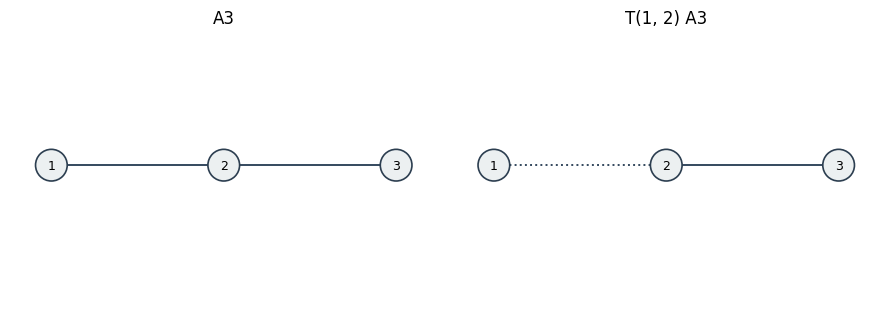

In [10]:
A3_FLATED = A3.flation(1, 2)
show_matrix_row(
    [
        ("A3 before", A3.matrix, A3.labels),
        ("T(1, 2) A3 after", A3_FLATED.matrix, A3_FLATED.labels),
    ],
)

fig, axes = plt.subplots(1, 2, figsize=(9.0, 3.2))
draw_bigraph(A3, A3_POSITIONS, ax=axes[0], title="A3")
draw_bigraph(A3_FLATED, A3_POSITIONS, ax=axes[1], title="T(1, 2) A3")
fig.tight_layout()
plt.show()

**Figure 1.** A3 and its flation from vertex 1 to vertex 2. Both diagrams keep three vertices and
the same fixed positions; only edge styles change.

In [11]:
assert A3_FLATED.matrix.inertia == A3.matrix.inertia == Inertia(3, 0, 0)
assert A3_FLATED.classify().components[0].dynkin_type == DynkinType("A", 3)
assert A3_FLATED.classify().status is ClassificationStatus.CLASSIFIED
assert A3_FLATED.matrix.entries == ((2, 1, 0), (1, 2, -1), (0, -1, 2))
display(Markdown("**Result.** Inertia `(3, 0, 0)` and Dynkin type `A_3` are preserved."))

**Result.** Inertia `(3, 0, 0)` and Dynkin type `A_3` are preserved.

## 4. A-type: A9 and its block-cut tree

**Theorem 2 (A-type).** A connected bigraph is of type `A_n` exactly when its block-cut tree is a
tree of A-blocks and every articulation point belongs to exactly two blocks. The certificate
below exhibits the blocks, the two sides of each A-block partition, and the articulation points.
It is a structural certificate: it is checked independently of `classify()`.

In [12]:
A9_TEXT = """1--2..3--1
3..4--5--3
3--9--4
5..9
5..6..8..5
4--7"""
A9 = graph(A9_TEXT, labels=tuple(range(1, 10)))
show_matrix(A9.matrix, A9.labels, caption="A9 matrix (labels 1..9)")

a9_certificate = A9.a_type_certificate()
assert a9_certificate is not None
a9_component = a9_certificate.components[0]
a9_tree = a9_component.tree
assert a9_certificate.verify(A9)
assert a9_component.dynkin_type == DynkinType("A", 9)
assert {frozenset(block.labels) for block in a9_tree.blocks} == {
    frozenset({1, 2, 3}),
    frozenset({3, 4, 5, 9}),
    frozenset({4, 7}),
    frozenset({5, 6, 8}),
}
assert a9_tree.articulation_points == (3, 4, 5)

block_lines = ["| block | labels | A-block sides |", "|---|---|---|"]
for index, (block, partition) in enumerate(
    zip(a9_tree.blocks, a9_component.partitions, strict=True),
    start=1,
):
    block_lines.append(
        f"| B{index} | {{{', '.join(str(label) for label in block.labels)}}} | "
        f"{{{', '.join(str(label) for label in partition.x)}}} | "
        f"{{{', '.join(str(label) for label in partition.y)}}} |",
    )
display(Markdown("\n".join(block_lines)))
articulation_text = ", ".join(str(label) for label in a9_tree.articulation_points)
display(
    Markdown(
        f"**Articulation points:** {articulation_text}. The certificate verifies.",
    ),
)

,1,2,3,4,5,6,7,8,9
1,2,-1,-1,0,0,0,0,0,0
2,-1,2,1,0,0,0,0,0,0
3,-1,1,2,1,-1,0,0,0,-1
4,0,0,1,2,-1,0,-1,0,-1
5,0,0,-1,-1,2,1,0,1,1
6,0,0,0,0,1,2,0,1,0
7,0,0,0,-1,0,0,2,0,0
8,0,0,0,0,1,1,0,2,0
9,0,0,-1,-1,1,0,0,0,2


| block | labels | A-block sides |
|---|---|---|
| B1 | {1, 2, 3} | {2, 3} | {1} |
| B2 | {3, 4, 5, 9} | {5, 9} | {3, 4} |
| B3 | {4, 7} | {7} | {4} |
| B4 | {5, 6, 8} | {5, 6, 8} | {} |

**Articulation points:** 3, 4, 5. The certificate verifies.

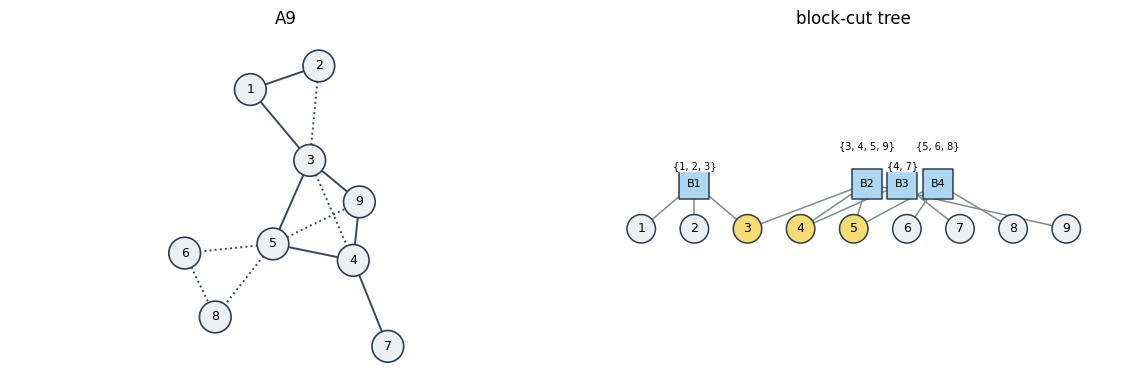

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.0))
draw_bigraph(A9, A9_POSITIONS, ax=axes[0], title="A9")
draw_block_cut_tree(a9_tree, ax=axes[1], title="block-cut tree")
fig.tight_layout()
plt.show()

**Figure 2.** A9 and its block-cut tree. The blocks are `{1,2,3}`, `{3,4,5,9}`, `{4,7}`, and
`{5,6,8}`; the articulation points `3`, `4`, and `5` are highlighted. Each cut vertex belongs to
exactly two blocks, which is the structural A-type condition.

## 5. D-core gluing: D13

**Theorem 3 (D-core gluing).** Let `H` be an odd cycle of solid and dotted edges. Glue one
connected positive definite A-type piece onto each core edge, so that consecutive pieces meet
exactly at the shared core vertex and the core endpoints are internal vertices of their pieces.
The resulting bigraph has type `D_n`, where `n` is the number of vertices in the union.

The core below is the odd five-cycle `1 - 2 - 3 - 4 - 5 - 1` with three dotted edges. The five
pieces are A3, A4, A2, A7, and A2; their core edges occur in the order of the cycle.

In [14]:
D13_CORE_BIGRAPH = graph("1..2--3..4..5--1", labels=(1, 2, 3, 4, 5))
D13_CORE = DCore(EdgeMultiset.from_bigraph(D13_CORE_BIGRAPH))
D13_PIECES = (
    graph("1..2..8..1", labels=(1, 2, 8)),
    graph("2--3--6..2\n6--7", labels=(2, 3, 6, 7)),
    graph("3..4", labels=(3, 4)),
    graph(
        "4--10--5..4\n5..9..4\n9--10\n9--12..13--9\n10--11",
        labels=(4, 5, 9, 10, 11, 12, 13),
    ),
    graph("1--5", labels=(1, 5)),
)

show_matrix(D13_CORE_BIGRAPH.matrix, D13_CORE_BIGRAPH.labels, caption="D-core H")
assert all(piece.a_type_certificate() is not None for piece in D13_PIECES)
assert all(piece.matrix.inertia.is_positive_definite for piece in D13_PIECES)

piece_lines = ["| piece | core edge | vertex labels | A-type |", "|---|---|---|---|"]
core_labels = D13_CORE.labels
for index, (piece, first, second) in enumerate(
    zip(
        D13_PIECES,
        core_labels,
        (*core_labels[1:], core_labels[0]),
        strict=True,
    ),
    start=1,
):
    edge = next(
        edge
        for edge in D13_CORE.edges.edges
        if frozenset((edge.source, edge.target)) == frozenset((first, second))
    )
    operator = ".." if edge.style is EdgeStyle.DOTTED else "--"
    piece_type = piece.a_type_certificate()
    assert piece_type is not None
    piece_lines.append(
        f"| F{index} | {first} {operator} {second} | "
        f"{{{', '.join(str(label) for label in piece.labels)}}} | "
        f"`{piece_type.components[0].dynkin_type.name}` |",
    )
display(Markdown("\n".join(piece_lines)))

,1,2,3,4,5
1,2,1,0,0,-1
2,1,2,-1,0,0
3,0,-1,2,1,0
4,0,0,1,2,1
5,-1,0,0,1,2


| piece | core edge | vertex labels | A-type |
|---|---|---|---|
| F1 | 1 .. 2 | {1, 2, 8} | `A_3` |
| F2 | 2 -- 3 | {2, 3, 6, 7} | `A_4` |
| F3 | 3 .. 4 | {3, 4} | `A_2` |
| F4 | 4 .. 5 | {4, 5, 9, 10, 11, 12, 13} | `A_7` |
| F5 | 5 -- 1 | {1, 5} | `A_2` |

In [15]:
D13 = D13_CORE.gluing(D13_PIECES, labels=tuple(range(1, 14)))
assert D13.verify()
assert D13.dynkin_type == DynkinType("D", 13)
assert D13.gluing.classify().components[0].dynkin_type == DynkinType("D", 13)
assert D13.gluing.labels == tuple(range(1, 14))
show_matrix(D13.gluing.matrix, D13.gluing.labels, collapse=True)

,1,2,3,4,5,6,7,8,9,10,11,12,13
1,2,1,0,0,-1,0,0,1,0,0,0,0,0
2,1,2,-1,0,0,1,0,1,0,0,0,0,0
3,0,-1,2,1,0,-1,0,0,0,0,0,0,0
4,0,0,1,2,1,0,0,0,1,-1,0,0,0
5,-1,0,0,1,2,0,0,0,1,-1,0,0,0
6,0,1,-1,0,0,2,-1,0,0,0,0,0,0
7,0,0,0,0,0,-1,2,0,0,0,0,0,0
8,1,1,0,0,0,0,0,2,0,0,0,0,0
9,0,0,0,1,1,0,0,0,2,-1,0,-1,-1
10,0,0,0,-1,-1,0,0,0,-1,2,-1,0,0


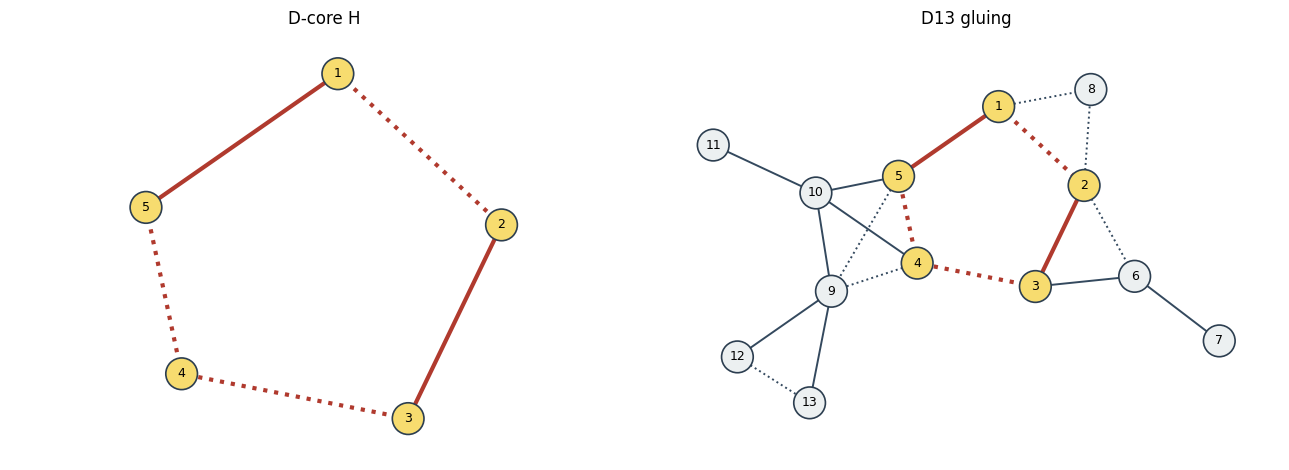

In [16]:
d13_core_edges = [frozenset((edge.source, edge.target)) for edge in D13_CORE.edges.edges]
fig, axes = plt.subplots(1, 2, figsize=(13.0, 4.8))
draw_bigraph(
    D13_CORE_BIGRAPH,
    D13_POSITIONS,
    ax=axes[0],
    title="D-core H",
    highlight_edges=d13_core_edges,
    highlight_nodes=D13_CORE.labels,
)
draw_bigraph(
    D13.gluing,
    D13_POSITIONS,
    ax=axes[1],
    title="D13 gluing",
    highlight_edges=d13_core_edges,
    highlight_nodes=D13_CORE.labels,
)
fig.tight_layout()
plt.show()

**Figure 3.** The D-core `H` and the resulting D13 graph. The five core edges are highlighted in
red and the five core vertices are filled; all remaining edges belong to the A-type pieces. The
gluing certificate recomputes from the pieces and verifies, and `classify()` independently reports
`D_13`.

## 6. A-cyclization: A9 to D8

**Theorem 4 (A-cyclization).** Identify two internal vertices `x` and `y` of a connected positive
definite A-type bigraph. If the unique shortest `x`-to-`y` path has an odd number of dotted edges,
the identification produces a positive definite `D_(n-1)` bigraph. The certificate records `x`,
`y`, the path, and the result, and verifies by recomputing the identification.

For A9 we identify vertices `1` and `6`. The unique shortest path is `1 - 3 - 5 - 6`; it has one
dotted edge, namely `3-5`. The result has eight vertices and labels `(1, 2, 3, 4, 5, 7, 8, 9)`.

In [17]:
A9_CYCLIZATION = A9.a_cyclization(1, 6)
assert A9_CYCLIZATION.verify()
assert A9_CYCLIZATION.path == (1, 3, 5, 6)
assert A9_CYCLIZATION.dynkin_type == DynkinType("D", 8)
assert A9_CYCLIZATION.result.labels == (1, 2, 3, 4, 5, 7, 8, 9)
assert A9_CYCLIZATION.result.dimension == A9_CYCLIZATION.dynkin_type.rank
assert A9_CYCLIZATION.result.classify().components[0].dynkin_type == DynkinType("D", 8)

show_matrix(
    A9_CYCLIZATION.result.matrix,
    A9_CYCLIZATION.result.labels,
    caption="D8 matrix (vertex 1=6, labels 1, 2, 3, 4, 5, 7, 8, 9)",
)
display(
    Markdown(
        f"**Path:** `{' - '.join(str(label) for label in A9_CYCLIZATION.path)}`; "
        f"**type:** `{A9_CYCLIZATION.dynkin_type.name}`; "
        f"**vertex count:** `{A9_CYCLIZATION.result.dimension}`.",
    ),
)

,1,2,3,4,5,7,8,9
1,2,-1,-1,0,1,0,1,0
2,-1,2,1,0,0,0,0,0
3,-1,1,2,1,-1,0,0,-1
4,0,0,1,2,-1,-1,0,-1
5,1,0,-1,-1,2,0,1,1
7,0,0,0,-1,0,2,0,0
8,1,0,0,0,1,0,2,0
9,0,0,-1,-1,1,0,0,2


**Path:** `1 - 3 - 5 - 6`; **type:** `D_8`; **vertex count:** `8`.

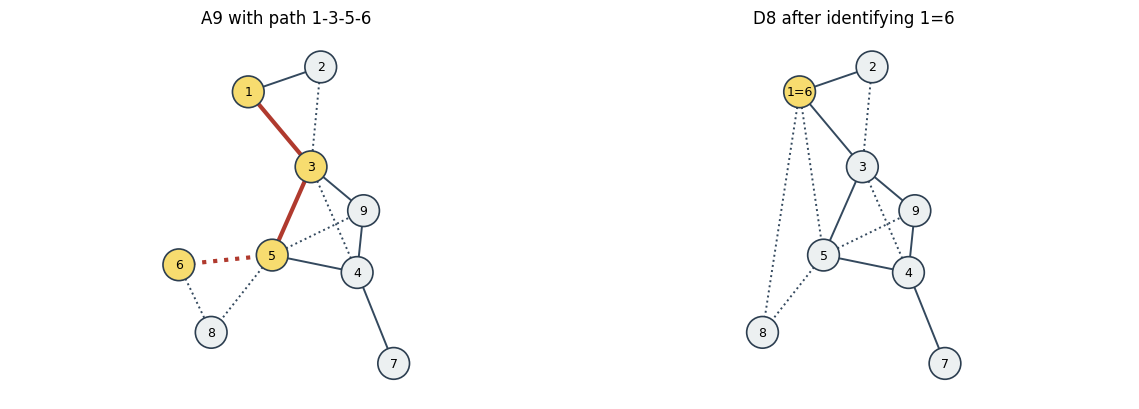

In [18]:
cyclization_path_edges = {
    frozenset((A9_CYCLIZATION.path[index], A9_CYCLIZATION.path[index + 1]))
    for index in range(len(A9_CYCLIZATION.path) - 1)
}
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
draw_bigraph(
    A9,
    A9_POSITIONS,
    ax=axes[0],
    title="A9 with path 1-3-5-6",
    highlight_edges=cyclization_path_edges,
    highlight_nodes=A9_CYCLIZATION.path,
)
draw_bigraph(
    A9_CYCLIZATION.result,
    D8_POSITIONS,
    ax=axes[1],
    title="D8 after identifying 1=6",
    display_labels={1: "1=6"},
    highlight_nodes=(1,),
)
fig.tight_layout()
plt.show()

**Figure 4.** The A9 cyclization. The unique shortest path `1-3-5-6` is highlighted on the left;
the identified vertex is drawn as `1=6` on the right. The certificate verifies and the result is
`D_8`. The D8 labels are not contiguous, which is why the matrix table uses explicit labels.

## 7. The algorithm and the boundary table

The thesis's classification strategy has three layers. First, exact inertia rejects matrices that
are not positive definite. Second, every connected component with at most eight vertices is
reduced by bounded flations to a solid normal form and read as a Dynkin diagram. Third, above that
range, E-types are excluded and the A- and D-types are recognized structurally: A-types by their
block-cut trees, D-types by the D-core gluing or the A-cyclization certificates.

`classify()` in DynkinLab is an independent exact oracle for this notebook. It uses a bounded
flation search and returns a replayable witness; it is **not** a reimplementation of the thesis's
Bareiss plus structural polynomial algorithm. The structural certificates in Sections 4-6 are
checked separately from `classify()`.

The table includes finite types, a mixed B6 example, an affine matrix, and the matrix-only `2/4`
case. The certificate column names only the structural certificates constructed in this notebook.

In [19]:
B6 = graph(
    """1--2--3..1
3.>6
3--4..5--3
4->6
5->6""",
    labels=tuple(range(1, 7)),
)
E6 = Bigraph(DynkinType("E", 6).cartan_matrix(), tuple(range(1, 7)))
AFFINE_A2 = graph("1--2--3--1", labels=(1, 2, 3))

boundary_cases = (
    ("A9", A9.matrix, A9.labels, "A-type"),
    ("D13", D13.gluing.matrix, D13.gluing.labels, "D-core"),
    ("D8", A9_CYCLIZATION.result.matrix, A9_CYCLIZATION.result.labels, "A-cyclization"),
    ("E6", E6.matrix, E6.labels, "None"),
    ("mixed B6", B6.matrix, B6.labels, "None"),
    ("affine A2", AFFINE_A2.matrix, AFFINE_A2.labels, "None"),
    ("2/4 matrix", bad_matrix, (1, 2), "None"),
)

boundary_rows: dict[str, tuple[str, str, str]] = {}
boundary_lines = [
    "| case | inertia | classifier outcome | faithful bigraph | certificate |",
    "|---|---|---|---|---|",
]
for name, matrix, _labels, certificate in boundary_cases:
    result = matrix.classify()
    outcome = (
        result.components[0].dynkin_type.name
        if result.status is ClassificationStatus.CLASSIFIED
        else result.status.name
    )
    bigraph_status = "yes" if has_faithful_bigraph(matrix) else "no"
    boundary_rows[name] = (outcome, bigraph_status, certificate)
    boundary_lines.append(
        f"| {name} | ({matrix.inertia.positive}, {matrix.inertia.negative}, "
        f"{matrix.inertia.zero}) | `{outcome}` | {bigraph_status} | {certificate} |",
    )

caption = (
    "**Table 1.** Boundary cases. The classifier column is the output of `classify()`, an exact "
    "bounded-flation oracle, not the thesis's Bareiss plus structural polynomial algorithm. "
    "`2/4 matrix` is the only row without a faithful bigraph."
)
display(Markdown(caption + "\n\n" + "\n".join(boundary_lines)))

assert boundary_rows["A9"] == ("A_9", "yes", "A-type")
assert boundary_rows["D13"] == ("D_13", "yes", "D-core")
assert boundary_rows["D8"] == ("D_8", "yes", "A-cyclization")
assert boundary_rows["E6"] == ("E_6", "yes", "None")
assert boundary_rows["mixed B6"] == ("B_6", "yes", "None")
assert boundary_rows["affine A2"] == ("NOT_POSITIVE_DEFINITE", "yes", "None")
assert boundary_rows["2/4 matrix"] == ("NOT_ADMISSIBLE", "no", "None")
assert AFFINE_A2.matrix.inertia == Inertia(2, 0, 1)
assert bad_matrix.inertia == Inertia(1, 1, 0)

**Table 1.** Boundary cases. The classifier column is the output of `classify()`, an exact bounded-flation oracle, not the thesis's Bareiss plus structural polynomial algorithm. `2/4 matrix` is the only row without a faithful bigraph.

| case | inertia | classifier outcome | faithful bigraph | certificate |
|---|---|---|---|---|
| A9 | (9, 0, 0) | `A_9` | yes | A-type |
| D13 | (13, 0, 0) | `D_13` | yes | D-core |
| D8 | (8, 0, 0) | `D_8` | yes | A-cyclization |
| E6 | (6, 0, 0) | `E_6` | yes | None |
| mixed B6 | (6, 0, 0) | `B_6` | yes | None |
| affine A2 | (2, 0, 1) | `NOT_POSITIVE_DEFINITE` | yes | None |
| 2/4 matrix | (1, 1, 0) | `NOT_ADMISSIBLE` | no | None |

## References

1. M. Abarca, *La clasificación Dynkin en perspectiva computacional*, doctoral thesis,
   Universidad Autónoma del Estado de Morelos.
2. M. Barot, "Geometric invariants of quivers and quasi-Cartan matrices", and the A/D structural
   constructions cited in the thesis.
3. DynkinLab documentation and source: <https://github.com/knkillname/dynkinlab>.

In [20]:
assert a9_certificate is not None
assert a9_certificate.verify(A9)
assert D13.verify()
assert A9_CYCLIZATION.verify()
assert A3_FLATED.matrix.inertia == A3.matrix.inertia == Inertia(3, 0, 0)
assert boundary_rows["2/4 matrix"][1] == "no"
assert boundary_rows["2/4 matrix"][0] == ClassificationStatus.NOT_ADMISSIBLE.name

print(f"DynkinLab {dynkinlab.__version__}")
print("All certificates verified.")

DynkinLab 0.0.1
All certificates verified.
